<a href="https://colab.research.google.com/github/yurajsinghyadav33-dotcom/NumPy-Image-Processing-Toolkit/blob/main/NumPy_Image_Processing_Toolkit11.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Original image shape: (512, 512, 3)


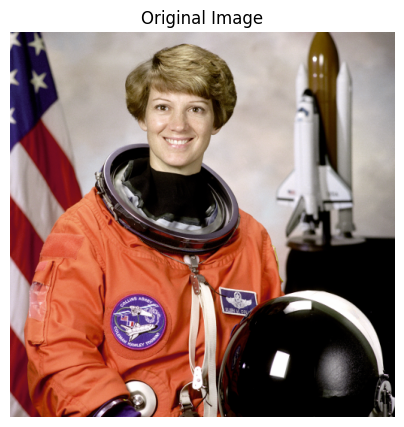

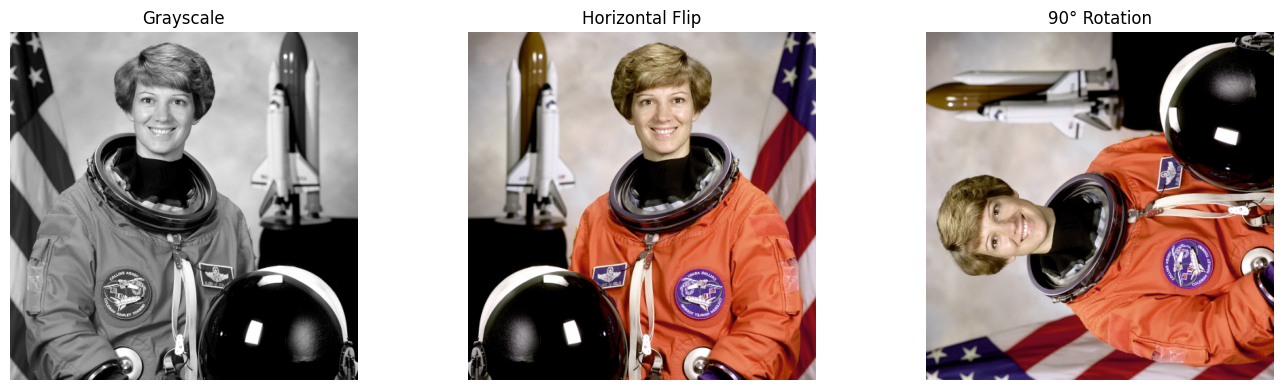

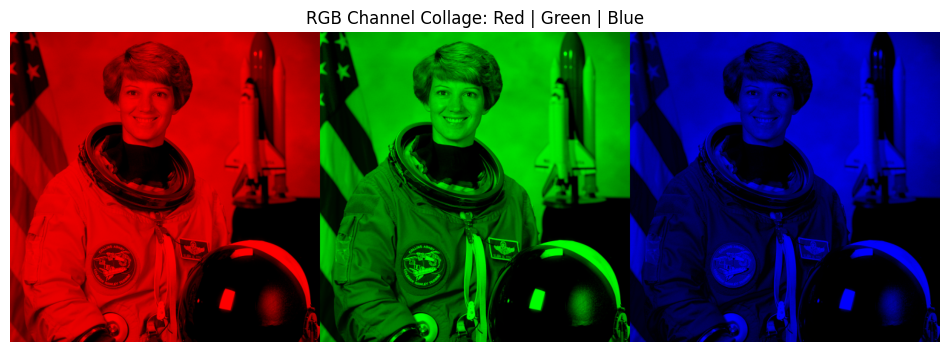

Both methods match: True
628 µs ± 192 µs per loop (mean ± std. dev. of 7 runs, 1000 loops each)
48.8 ms ± 24.5 ms per loop (mean ± std. dev. of 7 runs, 10 loops each)


In [1]:
# If needed, uncomment and run this line once:
# !pip install scikit-image

import numpy as np
import matplotlib.pyplot as plt
from skimage import data
import timeit

np.random.seed(42)

# Load a built-in sample image
image = data.astronaut()
print("Original image shape:", image.shape)

plt.figure(figsize=(5, 5))
plt.imshow(image)
plt.title("Original Image")
plt.axis("off")
plt.show()
# 1. Grayscale conversion using NumPy array operations
gray = np.dot(image[..., :3], [0.299, 0.587, 0.114])

# 2. Horizontal flip and 90-degree rotation using transpose
flipped = image[:, ::-1, :]
rotated = np.transpose(image, (1, 0, 2))[::-1, :, :]

fig, axes = plt.subplots(1, 3, figsize=(14, 4))
axes[0].imshow(gray, cmap="gray")
axes[0].set_title("Grayscale")
axes[1].imshow(flipped)
axes[1].set_title("Horizontal Flip")
axes[2].imshow(rotated)
axes[2].set_title("90° Rotation")
for ax in axes:
    ax.axis("off")
plt.tight_layout()
plt.show()
# 3. Split RGB channels and stack them into a collage
red = image[:, :, 0]
green = image[:, :, 1]
blue = image[:, :, 2]

red_image = np.stack([red, np.zeros_like(red), np.zeros_like(red)], axis=2)
green_image = np.stack([np.zeros_like(green), green, np.zeros_like(green)], axis=2)
blue_image = np.stack([np.zeros_like(blue), np.zeros_like(blue), blue], axis=2)

collage = np.concatenate([red_image, green_image, blue_image], axis=1)

plt.figure(figsize=(12, 5))
plt.imshow(collage)
plt.title("RGB Channel Collage: Red | Green | Blue")
plt.axis("off")
plt.show()
# 4. Compare vectorized grayscale conversion with pixel loops
def vectorized_gray(img):
    return np.dot(img[..., :3], [0.299, 0.587, 0.114])

def loop_gray(img):
    h, w, _ = img.shape
    result = np.zeros((h, w), dtype=float)
    for i in range(h):
        for j in range(w):
            r, g, b = img[i, j, :3]
            result[i, j] = 0.299*r + 0.587*g + 0.114*b
    return result

# Use a smaller image to keep the loop benchmark practical
small_image = image[::8, ::8, :]

print("Both methods match:",
      np.allclose(vectorized_gray(small_image), loop_gray(small_image)))

# %timeit is available in Google Colab
%timeit vectorized_gray(small_image)
%timeit loop_gray(small_image)
